In [1]:
#1. Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [16]:
import pandas as pd

# 2. Membaca dataset
data = pd.read_csv("../dataset.csv")
print("Jumlah data:", len(data))
#3. Melihat Data Awal
#menampilkan 10 data teratas
print(data.head(10))

#Melihat 10 data terakhir
print(data.tail(10))

Jumlah data: 3376
  date_publication media_source  \
0       2026-01-01       Kontan   
1       2026-01-01       Kontan   
2       2026-01-01       Kontan   
3       2026-01-01       Kontan   
4       2026-01-01       Kontan   
5       2026-01-01       Kontan   
6       2026-01-01       Kontan   
7       2026-01-01       Kontan   
8       2026-01-01       Kontan   
9       2026-01-01       Kontan   

                                       title_article  \
0  Harga Emas Antam Hari Ini (28/3) Naik Rp 27.00...   
1  Kejagung Tetapkan Samin Tan Tersangka, Ini Kas...   
2  Asing Net Sell Rp 20,38 Triliun, Cek Saham yan...   
3                          Berburu Emas di Pagi Buta   
4  Hampir Rampung, ESDM Restui RKAB Batubara 580 ...   
5  Iran Beri Sinyal Positif, 2 Kapal Tanker Perta...   
6  Yuk Lihat Harga Emas Hari Ini di Pegadaian Sab...   
7  Indocement Tunggal Prakarsa (INTP) Bentuk Usah...   
8  Naik Rp 27.000 Per Gram, Cek Harga Emas Antam ...   
9  Bursa Wall Street Memerah di Akhi

In [14]:
#4. Melihat Informasi Dataset

# Info dataset
data.info()

# Ukuran dataset
print(data.shape)


<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date_publication  3376 non-null   str    
 1   media_source      3376 non-null   str    
 2   title_article     3376 non-null   str    
 3   content_article   3376 non-null   str    
 4   url_article       3376 non-null   str    
 5   sentiment_label   3376 non-null   str    
 6   polarity_score    3376 non-null   float64
 7   ai_confidence     3376 non-null   float64
dtypes: float64(2), str(6)
memory usage: 211.1 KB
(3376, 8)


In [15]:
#5. Melihat Nama Kolom
print(data.columns)

Index(['date_publication', 'media_source', 'title_article', 'content_article',
       'url_article', 'sentiment_label', 'polarity_score', 'ai_confidence'],
      dtype='str')


In [12]:
#6. Jumlah Dokumen
jumlah_dokumen = len(data)
print("Jumlah dokumen:", jumlah_dokumen)

Jumlah dokumen: 3376


In [22]:
#7. Memilih kolom Teks
text_column = "content_article"
text_data = data[text_column]

#contoh teks
for text in text_data.head(10):
    print(text)
    print("-" * 80)

Reporter: Noverius Laoli | Editor: Noverius Laoli KONTAN.CO.ID - JAKARTA.  Harga emas batangan bersertifikat Antam keluaran Logam Mulia PT Aneka Tambang Tbk (ANTM) naik pada Sabtu (28/3/2026). Mengutip situs Logam Mulia, harga pecahan satu gram emas Antam berada di Rp 2.837.000. Harga emas Antam itu naik dibandingkan dengan harga pada Jumat (27/3/2026) yang berada di level Rp 2.810.000 per gram. Sementara harga buyback emas Antam berada di level Rp 2.461.000 per gram. Harga tersebut naik Rp 47.000 jika dibandingkan dengan harga buyback pada Jumat (27/3/2026) yang juga ada di Rp 2.414.000 per gram. Berikut harga emas batangan Antam dalam pecahan lainnya per Sabtu (28/3/2026) dan belum termasuk pajak:  Harga emas 0,5 gram: Rp 1.468.000 Harga emas 1 gram: Rp 2.837.000 Harga emas 5 gram: Rp 13.960.000 Harga emas 10 gram: Rp 27.865.000 Harga emas 25 gram: Rp 69.537.000 Harga emas 50 gram: Rp 138.995.000 Harga emas 100 gram: Rp 277.912.000 Harga emas 250 gram: Rp 694.515.000 Harga emas 500 g

In [54]:
#8. Memeriksa Missing Values
print("Missing value per kolom:")
print(data.isnull().sum())

print("\nMissing value pada kolom teks:", data[text_column].isnull().sum())

# menghapus data kosong
sebelum = len(data)
data = data.dropna(subset=[text_column])
print("Dokumen dihapus karena kosong:", sebelum - len(data))
print("Missing value setelah dihapus:", data[text_column].isnull().sum())

Missing value per kolom:
date_publication    0
media_source        0
title_article       0
content_article     0
url_article         0
sentiment_label     0
polarity_score      0
ai_confidence       0
junlah_karakter     0
jumlah_karakter     0
jumlah_kata         0
jumlah_kalimat      0
dtype: int64

Missing value pada kolom teks: 0
Dokumen dihapus karena kosong: 0
Missing value setelah dihapus: 0


In [25]:
#9. Memeriksa Duplikasi
print("Duplikat (seluruh baris)      :", data.duplicated().sum())
print("Duplikat (pada kolom teks)    :", data[text_column].duplicated().sum())

# menghapus duplikasi
sebelum = len(data)
data = data.drop_duplicates(subset=[text_column])
print("Dokumen dihapus karena duplikat:", sebelum - len(data))
print("Jumlah dokumen sekarang        :", len(data))

Duplikat (seluruh baris)      : 0
Duplikat (pada kolom teks)    : 22
Dokumen dihapus karena duplikat: 22
Jumlah dokumen sekarang        : 3354


In [35]:
#10. Menghitung Jumlah Karakter
data["jumlah_karakter"] = data[text_column].astype(str).apply(len)
data[[text_column, "jumlah_karakter"]].head()

,content_article,jumlah_karakter
0,Reporter: Noverius Laoli | Editor: Noverius La...,1528
1,Reporter: kompas.com | Editor: Noverius Laoli ...,2179
2,Reporter: Noverius Laoli | Editor: Noverius La...,1987
3,Format Non-Text/Gagal Ekstrak,29
4,Reporter: Sabrina Rhamadanty | Editor: Ignatia...,1788


In [36]:
#11. Menghitung Jumlah Kata
data["jumlah_kata"] = data[text_column].astype(str).apply(lambda x: len(x.split()))
data[[text_column, "jumlah_kata"]].head()

,content_article,jumlah_kata
0,Reporter: Noverius Laoli | Editor: Noverius La...,243
1,Reporter: kompas.com | Editor: Noverius Laoli ...,262
2,Reporter: Noverius Laoli | Editor: Noverius La...,302
3,Format Non-Text/Gagal Ekstrak,3
4,Reporter: Sabrina Rhamadanty | Editor: Ignatia...,250


In [ ]:
#statistik jumlah kata
data["jumlah_kata"].describe()

count    3354.000000
mean      384.633870
std       175.639316
min         3.000000
25%       269.000000
50%       361.000000
75%       463.000000
max      1438.000000
Name: jumlah_kata, dtype: float64

In [40]:
#12. Menghitung jumlah kalimat
from nltk.tokenize import sent_tokenize

data["jumlah_kalimat"] = data[text_column].astype(str).apply(lambda x: len(sent_tokenize(x)))
data[[text_column, "jumlah_kalimat"]].head()

,content_article,jumlah_kalimat
0,Reporter: Noverius Laoli | Editor: Noverius La...,10
1,Reporter: kompas.com | Editor: Noverius Laoli ...,18
2,Reporter: Noverius Laoli | Editor: Noverius La...,25
3,Format Non-Text/Gagal Ekstrak,1
4,Reporter: Sabrina Rhamadanty | Editor: Ignatia...,15


In [39]:
#13. Statistik Corpus
print("jumlah_dokumen :", len(data))
print("jumlah_kata :", data["jumlah_kata"].sum())
print("jumlah_kalimat :", data["jumlah_kalimat"].sum())
print("jumlah_karakter :", data["jumlah_karakter"].sum())


jumlah_dokumen : 3354
jumlah_kata : 1290062
jumlah_kalimat : 71153
jumlah_karakter : 9389631


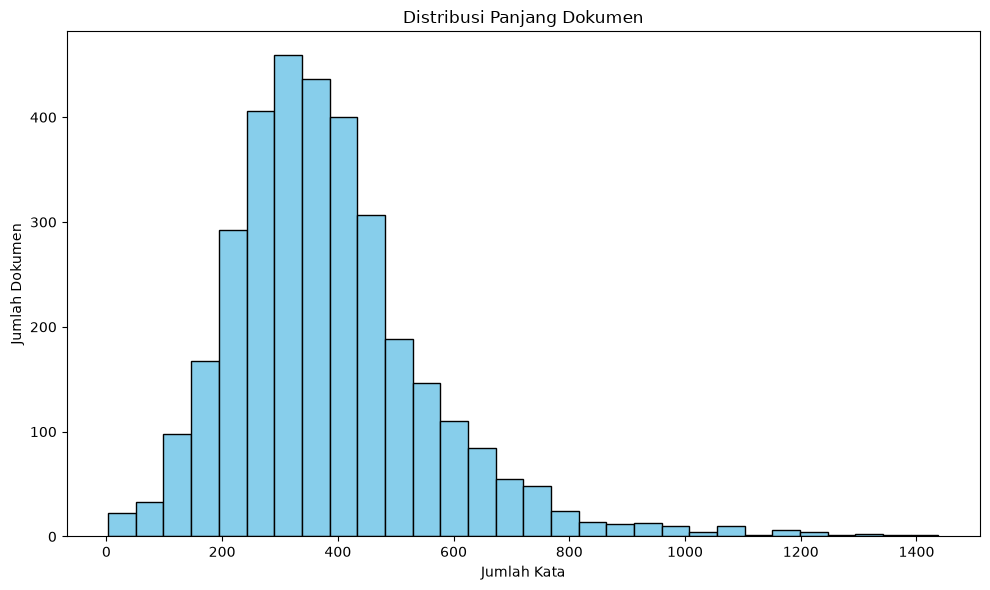

In [44]:
#14. Visualisasi Distribusi Panjang Dokumen
plt.figure(figsize=(10, 6))
plt.hist(data["jumlah_kata"], bins=30, color='skyblue', edgecolor='black')
plt.xlabel('Jumlah Kata')
plt.ylabel('Jumlah Dokumen')
plt.title('Distribusi Panjang Dokumen')
plt.tight_layout()
plt.show()

Jumlah per label:
sentiment_label
NETRAL     3061
NEGATIF     181
POSITIF     112
Name: count, dtype: int64

Persentase per label (%):
sentiment_label
NETRAL     91.26
NEGATIF     5.40
POSITIF     3.34
Name: proportion, dtype: float64


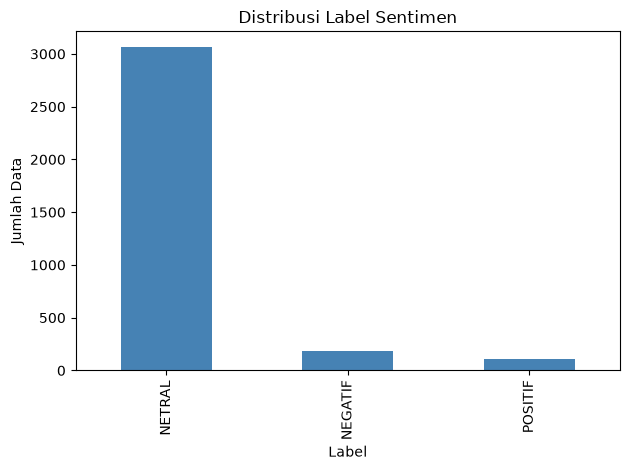

In [26]:
# 16. Distribusi Label (Jika Ada)
data["sentiment_label"].value_counts().plot(
    kind="bar",
    color="steelblue"
)

#menampilkan angka pasti
print("Jumlah per label:")
print(data["sentiment_label"].value_counts())

print("\nPersentase per label (%):")
print((data["sentiment_label"].value_counts(normalize=True) * 100).round(2))

plt.xlabel("Label")
plt.ylabel("Jumlah Data")
plt.title("Distribusi Label Sentimen")
plt.tight_layout()
plt.show()